# Fig. 6f: weights of the model of sorting accuracy for Kilosort 4 (biophysical, evoked, Neuropixels)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel f of the paper: the weights of the fractional regression (binomial GLM with logit link) that models the sorting accuracy of each ground truth neuron from its biological features (same neurons, features and model as fig6d.ipynb). Source data and svg are saved in figures/8_source_data/fig6f/.

**method (the paper's model, as in the paper's notebook fig6_D_F_fracreg_E_ks4.ipynb)**
* ground truth: first 10 minutes of the biophysical evoked simulation; sorting: Kilosort 4 (10 min); sorting accuracy = best agreement score (delta_time = 1.3 ms) with a sorted unit
* features: firing rate, synapse class, etype and layer (one-hot), distance to the nearest site (3D), SNR and spatial extent of the ground truth waveforms, exc_mini_frequency, dynamics_holding_current (`model_template` is dropped). The evoked simulation has two more etypes (bIR, cIR) than the spontaneous one: they are in the model but, as in the paper's panel, not shown (their weights are in the second sheet of the source data)
* the features are z-scored over the neurons: a weight is the change in the log-odds of the accuracy for an increase of one standard deviation of a feature
* the model is fitted on all neurons with a complete set of features; lasso setting of the paper's code (elastic net with alpha = 0, 100 iterations, tolerance 1e-10), then refitted for one iteration
* p-value of each weight: Wald test of the fitted model. Weights significantly different from 0 (p < 0.05) are in pink; stars: *: p < 0.05, **: p < 0.01, ***: p < 0.001
* the features are in the same order as in panel e (spontaneous model), and the feature names are written in panel e only, as in the paper

In [1]:
%load_ext autoreload
%autoreload 2
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "1"
import copy
import numpy as np
import pandas as pd
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.core.template_tools as ttools
from spikeinterface import extract_waveforms
from spikeinterface import qualitymetrics as qm
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# set project path
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(PROJ_PATH)

# custom package
from src.nodes.metrics import metrics
from src.nodes.models.Fr import dataloader as fr_dataloader
from src.nodes.models.Fr.models import FrModel

# paths
RECORDING_PATH = "dataset/00_raw/recording_npx_evoked/"
GT_PATH = "dataset/00_raw/ground_truth_npx_evoked_10m"          # first 10 min
KS4_PATH = "dataset/01_intermediate/sorting/npx_evoked/SortingKS4_10m/"

# parameters
FREQ_MIN = 300
REFERENCE = "global"
OPERATOR = "median"
MS_BEFORE = 3
MS_AFTER = 3
DURATION_SEC = 600
DT = 1.3
MAX_SPIKES_PER_UNIT = 500
SEED = 0
JOB_KWARGS = dict(n_jobs=16, chunk_duration="1s", progress_bar=False)

# FIGURE SETTINGS
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1
legend_cfg = {"frameon": False, "handletextpad": 0.5}

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

## Load the datasets

In [2]:
%%time

# recording (first 10 minutes, as for the sorting)
Recording = si.load_extractor(RECORDING_PATH)
Recording.set_property("location", Recording.get_property("location")[:, :2])
Recording = spre.highpass_filter(Recording, freq_min=FREQ_MIN)
Recording = spre.common_reference(Recording, reference=REFERENCE, operator=OPERATOR)
Recording = Recording.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))

# ground truth and sorting
SortingTrue = si.load_extractor(GT_PATH)
Sorting = si.load_extractor(KS4_PATH)
display(Recording)
display(SortingTrue)
display(Sorting)

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/spikeinterface/core/base.py:1079: UserWarning: Versions are not the same. This might lead to compatibility errors. Using spikeinterface==0.101.2 is recommended
  warnings.warn(


FrameSliceRecording: 384 channels - 20.0kHz - 1 segments - 12,000,000 samples 
                     600.00s (10.00 minutes) - float32 dtype - 17.17 GiB

NumpyFolderSorting: 1836 units - 1 segments - 20.0kHz

NumpyFolderSorting: 3529 units - 1 segments - 20.0kHz

CPU times: user 5.95 ms, sys: 2.85 ms, total: 8.8 ms
Wall time: 8.68 ms


## Ground truth waveforms (in memory; sparse, 6 ms window)

In [3]:
%%time

We = extract_waveforms(Recording, SortingTrue, folder=None, mode="memory", sparse=True, ms_before=MS_BEFORE, ms_after=MS_AFTER,
                       max_spikes_per_unit=MAX_SPIKES_PER_UNIT, seed=SEED, **JOB_KWARGS)
display(We)

WaveformExtractor: 384 channels - 1836 units - 1 segments
  before:60 after:60 n_per_units:500 - sparse

CPU times: user 10.5 s, sys: 13.4 s, total: 23.9 s
Wall time: 2min 22s


## Dataset: predictors (ground truth neuron features) and target (sorting accuracy)

In [4]:
%%time

dataset = pd.DataFrame()

# firing rate
n_spikes = SortingTrue.get_total_num_spikes()
dataset["firing_rate"] = [n_spikes[unit] / DURATION_SEC for unit in n_spikes]

# synapse class
dataset = fr_dataloader.set_synapse_class(dataset, SortingTrue)

# etype (one-hot)
dataset = pd.merge(dataset, pd.get_dummies(SortingTrue.get_property("etype")), left_index=True, right_index=True)

# layer (one-hot)
layers = np.array(["2/3" if (w == "2") or (w == "3") else w for w in SortingTrue.get_property("layer")])
layer_df = pd.get_dummies(layers)
layer_df.columns = ["layer_1", "layer_23", "layer_4", "layer_5", "layer_6"]
dataset = pd.merge(dataset, layer_df, left_index=True, right_index=True)

# 3D site coordinates (the recording's "location" property; get_probe().contact_positions has a null z for this recording)
Rec = si.load_extractor(RECORDING_PATH)
channel_coord = Rec.get_property("location")
channel_ids = Rec.get_channel_ids()

# distance to the nearest site (um)
unit_xyz = np.c_[SortingTrue.get_property("x"), SortingTrue.get_property("y"), SortingTrue.get_property("z")]
dataset["distance"] = [np.min(np.linalg.norm(channel_coord - xyz, axis=1)) for xyz in unit_xyz]

# signal-to-noise ratio
snrs = qm.compute_snrs(We, peak_sign="neg", peak_mode="extremum", unit_ids=We.sorting.unit_ids)
dataset["snr"] = snrs.values()

# spike spatial extent
max_chids = ttools.get_template_extremum_channel(We, peak_sign="neg")
dataset["spatial_extent"] = [
    metrics.get_spatial_spread(We, unit, max_chids, channel_ids, channel_coord)["spatial_spread"] for unit in We.unit_ids
]

# other features
dataset["exc_mini_frequency"] = SortingTrue.get_property("exc_mini_frequency")
dataset["dynamics_holding_current"] = SortingTrue.get_property("dynamics_holding_current")

# target: sorting accuracy
dataset["sorting_accuracy"] = fr_dataloader.get_accuracy(Sorting, SortingTrue, delta_time=DT).values
dataset.index = SortingTrue.unit_ids

# curate: drop units with an infinite feature. Units without spikes in the 10 minutes have no waveform: their snr and
# spatial_extent are missing. As in the paper's pipeline they stay in the dataset used for cross-validation (the model
# fits ignore rows with a missing feature), and are removed for the figure
dataset = dataset.drop(index=dataset.index[dataset.sum(axis=1) == np.inf])
predictors = dataset.columns.drop(["sorting_accuracy"])
print("neurons:", len(dataset), "| with a missing feature:", int(dataset.isna().any(axis=1).sum()), "| predictors:", len(predictors))

/home/steeve/steeve/epfl/code/spikebias/envs/spikebias/lib/python3.9/site-packages/spikeinterface/core/base.py:1079: UserWarning: Versions are not the same. This might lead to compatibility errors. Using spikeinterface==0.101.2 is recommended
  warnings.warn(


neurons: 1836 | with a missing feature: 213 | predictors: 23
CPU times: user 4.64 s, sys: 544 ms, total: 5.18 s
Wall time: 5.18 s


## Model weights (paper's model, fitted on all neurons)

In [5]:
%%time

frmodel = FrModel(predictors, "sorting_accuracy", order=1)
fullresults = frmodel.evaluate_on_full_dataset(dataset=dataset, scale_data=True, regularization="elastic_net",
                                               maxiter=100, cnvrg_tol=1e-10, verbose=False)
fullmodel = fullresults["metric_data"]["model"]
print("neurons used by the fit:", int(fullmodel.nobs))

2026-11-02 13:10:45,156 - root - utils.py - evaluate_on_full_dataset - INFO - Z-scoring the dataset features...


2026-11-02 13:10:45,159 - root - utils.py - evaluate_on_full_dataset - INFO - Done Z-scoring.


2026-11-02 13:10:45,455 - root - utils.py - evaluate_on_full_dataset - INFO - Done training the model.


neurons used by the fit: 1623
CPU times: user 304 ms, sys: 0 ns, total: 304 ms
Wall time: 304 ms


## Source data: weight and significance of each feature

In [6]:
# features of panel e, from the first row at the bottom (as in the paper's notebook)
FEATURE_ORDER = ["firing_rate", "spatial_extent", "layer_5", "synapse_class", "cADpyr", "layer_4", "cACint", "dynamics_holding_current", "dSTUT", "layer_1", "bNAC",
                 "bSTUT", "cSTUT", "layer_23", "cNAC", "exc_mini_frequency", "snr", "bAC", "dNAC", "layer_6", "distance"]
LABELS = {"exc_mini_frequency": "exc_mini_freq", "dynamics_holding_current": "holding_current"}    # as in the paper's figure

table = pd.DataFrame({"feature": fullmodel.params.index.drop("Intercept"), "weight": fullmodel.params.drop("Intercept").values,
                      "std_error": fullmodel.bse.drop("Intercept").values, "p_value": fullmodel.pvalues.drop("Intercept").values})
table["significance"] = np.select([table["p_value"] < 0.001, table["p_value"] < 0.01, table["p_value"] < 0.05], ["***", "**", "*"], "")
table["n_neurons"] = int(fullmodel.nobs)

# plotted features (same 21 features and order as panel e); bIR and cIR exist only in the evoked simulation and are not shown
df = table.set_index("feature").loc[FEATURE_ORDER].reset_index()
df["feature"] = df["feature"].replace(LABELS)
df_not_plotted = table[~table["feature"].isin(FEATURE_ORDER)]
display(df.round(4)); display(df_not_plotted.round(4))
print("significant (plotted):", int((df["p_value"] < 0.05).sum()), "of", len(df))

,feature,weight,std_error,p_value,significance,n_neurons
0,firing_rate,0.6559,0.0823,0.0000,***,1623
1,spatial_extent,0.3147,0.0787,0.0001,***,1623
2,layer_5,0.2885,0.0722,0.0001,***,1623
3,synapse_class,0.1837,0.0445,0.0000,***,1623
4,cADpyr,0.1837,0.0445,0.0000,***,1623
5,layer_4,0.0010,0.0779,0.9894,,1623
6,cACint,0.0887,0.0725,0.2213,,1623
7,holding_current,-0.0830,0.1043,0.4265,,1623
8,dSTUT,-0.1164,0.1689,0.4906,,1623
9,layer_1,-0.0367,0.0717,0.6089,,1623


,feature,weight,std_error,p_value,significance,n_neurons
3,bIR,-0.0354,0.1228,0.7731,,1623
8,cIR,0.0184,0.2718,0.9459,,1623


significant (plotted): 7 of 21


In [7]:
PINK = "#f4667d"     # colour of the significant weights in the paper figure (RGB 244, 102, 125)

def plot_source_data(df: pd.DataFrame):
    """Weights of the z-scored features (bars, first row at the bottom); weights significantly different from 0 (p < 0.05) in pink;
    weights and stars written to the right of the bars. The feature names are in panel e"""

    fig, ax = plt.subplots(1, 1, figsize=(1.5, 2.6))
    sig = df["significance"].fillna("")
    ypos = np.arange(len(df))
    ax.barh(ypos, df["weight"], color=np.where(sig != "", PINK, "k"), height=0.8)
    for y_, (w, s) in enumerate(zip(df["weight"], sig)):
        ax.text(0.7, y_, f"{w:.2f}", va="center", ha="left")
        ax.text(1.4, y_, s, va="center", ha="left")

    # aesthetics
    ax.set_yticks(ypos); ax.set_yticklabels([])
    ax.set_ylim(-0.6, len(df) - 0.4)
    ax.set_xlim(-1.7, 2); ax.set_xticks([-1, 0, 1, 2])
    ax.set_xlabel("Weights of z-scored features")
    ax.set_title("Evoked model", fontweight="bold", fontsize=6.5)
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.spines["left"].set_position(("axes", -0.05))
    return fig, ax

## Plot and save the figure and the source data

CPU times: user 117 ms, sys: 3.47 ms, total: 120 ms
Wall time: 122 ms


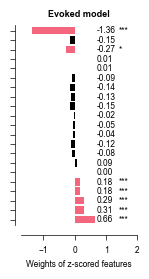

In [8]:
%%time

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig6f", exist_ok=True)
plt.savefig("figures/8_source_data/fig6f/fig6f.svg", bbox_inches="tight", **savefig_cfg)

# save source data (sheet 1: plotted weights; sheet 2: features of the model that are not plotted)
with pd.ExcelWriter("figures/8_source_data/fig6f/fig6f.xlsx") as writer:
    df.to_excel(writer, sheet_name="weights", index=False)
    df_not_plotted.to_excel(writer, sheet_name="not_plotted", index=False)

## Check: replot from the saved source data

CPU times: user 23.2 ms, sys: 0 ns, total: 23.2 ms
Wall time: 23.2 ms


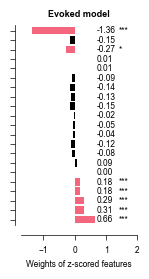

In [9]:
%%time

df = pd.read_excel("figures/8_source_data/fig6f/fig6f.xlsx", sheet_name="weights")
fig, ax = plot_source_data(df)